# Machine Learning Prediction of Steel Yield Strength

## Research Question

Can machine-learning models predict the yield strength of steels from chemical composition and processing information?

## Objective

To investigate whether incorporating processing information alongside chemical composition improves machine-learning prediction of steel yield strength.

In [22]:
import pandas as pd

df = pd.read_excel("data/Steel database with labelled clusters copy.xlsx")

print(df.shape)

(3234, 31)


In [23]:
print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

Dataset shape: (3234, 31)

Columns:
['Entry', 'Name', 'Processing condition', 'Unnamed: 3', 'Cluster Number (0 to 11)', 'Unnamed: 5', 'Al', 'Cu', 'Mn', 'N', 'Ni', 'Ti', 'S', 'Fe', 'Zr', 'P', 'Si', 'V', 'Mo', 'Co', 'C', 'Nb', 'B', 'Cr', 'Unnamed: 24', '(Ultimate) Tensile strength (MPa)', 'Yield strength (MPa)', 'Ductility (%)', 'Unnamed: 28', 'Cluster Number', 'Cluster label']


In [24]:
df.head()

,Entry,Name,Processing condition,Unnamed: 3,Cluster Number (0 to 11),Unnamed: 5,Al,Cu,Mn,N,...,Nb,B,Cr,Unnamed: 24,(Ultimate) Tensile strength (MPa),Yield strength (MPa),Ductility (%),Unnamed: 28,Cluster Number,Cluster label
0,1,AISI 4023 Steel,"Normalized At 925C (1700F), Machined To 25 mm ...",NaN,0,NaN,0.0,0.0,0.8,0.0,...,0.0,0.0,0.0,NaN,745,440,21,NaN,0,Carburized – quenched (oil) – wear-resistant s...
1,2,AISI 4027 Steel,"Water Quenched 865C (1590F), 540C (1000F) Temp...",NaN,10,NaN,0.0,0.0,0.8,0.0,...,0.0,0.0,0.0,NaN,689,510,25,NaN,10,Quenched (water) & tempered – high-strength st...
2,3,AISI 4027 Steel,"Water Quenched 865C (1590F), 480C (900F) Tempe...",NaN,10,NaN,0.0,0.0,0.8,0.0,...,0.0,0.0,0.0,NaN,786,615,22,NaN,10,Quenched (water) & tempered – high-strength st...
3,4,AISI 4027 Steel,"Water Quenched 865C (1590F), 480C (900F) Tempe...",NaN,10,NaN,0.0,0.0,0.8,0.0,...,0.0,0.0,0.0,NaN,1035,917,16,NaN,10,Quenched (water) & tempered – high-strength st...
4,5,AISI 4027 Steel,"Water Quenched 865C (1590F), 595C (1100F) Temp...",NaN,10,NaN,0.0,0.0,0.8,0.0,...,0.0,0.0,0.0,NaN,717,550,24,NaN,10,Quenched (water) & tempered – high-strength st...


In [25]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3234 entries, 0 to 3233
Data columns (total 31 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Entry                              3234 non-null   int64  
 1   Name                               3234 non-null   str    
 2   Processing condition               3234 non-null   str    
 3   Unnamed: 3                         0 non-null      float64
 4   Cluster Number (0 to 11)           3234 non-null   int64  
 5   Unnamed: 5                         0 non-null      float64
 6   Al                                 3234 non-null   float64
 7   Cu                                 3234 non-null   float64
 8   Mn                                 3234 non-null   float64
 9   N                                  3234 non-null   float64
 10  Ni                                 3234 non-null   float64
 11  Ti                                 3234 non-null   float64
 12  S  

## Dataset

The dataset contains 3,234 steel records and 31 columns.

The variables include chemical composition, processing-condition information, cluster information, mechanical properties, and cluster labels.

The prediction target for this project is:

**Yield strength (MPa)**

In [26]:
df["Yield strength (MPa)"].describe()

count    3234.000000
mean      648.439085
std       310.583216
min       159.000000
25%       415.000000
50%       596.000000
75%       841.000000
max      2395.000000
Name: Yield strength (MPa), dtype: float64

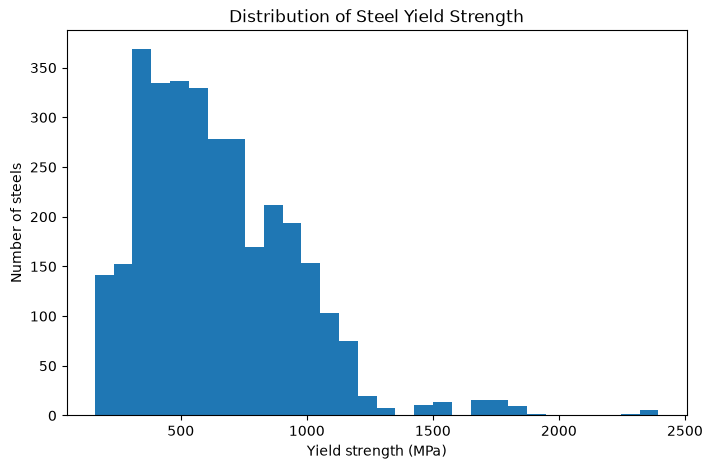

In [27]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(df["Yield strength (MPa)"], bins=30)
plt.xlabel("Yield strength (MPa)")
plt.ylabel("Number of steels")
plt.title("Distribution of Steel Yield Strength")
plt.show()

## Baseline Model: Chemical Composition Only

The first modelling stage uses only chemical composition to predict yield strength.

This provides a baseline against which models incorporating processing information can be compared.

In [28]:
composition_features = [
    "Al", "Cu", "Mn", "N", "Ni", "Ti", "S", "Fe",
    "Zr", "P", "Si", "V", "Mo", "Co", "C", "Nb", "B", "Cr"
]

X = df[composition_features]
y = df["Yield strength (MPa)"]

print("Features:", X.shape)
print("Target:", y.shape)

Features: (3234, 18)
Target: (3234,)


In [29]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 2587
Testing samples: 647


In [30]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split

composition_features = [
    "Al", "Cu", "Mn", "N", "Ni", "Ti", "S", "Fe",
    "Zr", "P", "Si", "V", "Mo", "Co", "C", "Nb", "B", "Cr"
]

X = df[composition_features]
y = df["Yield strength (MPa)"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

baseline_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

baseline_model.fit(X_train, y_train)

baseline_predictions = baseline_model.predict(X_test)

baseline_mae = mean_absolute_error(y_test, baseline_predictions)
baseline_r2 = r2_score(y_test, baseline_predictions)

print("Baseline MAE:", baseline_mae)
print("Baseline R²:", baseline_r2)

Baseline MAE: 149.96224051709473
Baseline R²: 0.5667490932873851


## Feature Engineering: Processing Information

The processing-condition field contains textual descriptions of heat treatment and dimensional information.

Instead of using the raw text directly, selected processing information was converted into structured numerical and categorical features.

These include:

- Tempering temperature
- Quench temperature
- Quench-stage type
- Number of reheat stages
- Case depth
- Round size
- Cluster number

In [31]:
process_columns = [
    "Cluster Number",
    "Processing condition"
]

df[process_columns].head()

,Cluster Number,Processing condition
0,0,"Normalized At 925C (1700F), Machined To 25 mm ..."
1,10,"Water Quenched 865C (1590F), 540C (1000F) Temp..."
2,10,"Water Quenched 865C (1590F), 480C (900F) Tempe..."
3,10,"Water Quenched 865C (1590F), 480C (900F) Tempe..."
4,10,"Water Quenched 865C (1590F), 595C (1100F) Temp..."


In [32]:
import re
import numpy as np

process = df["Processing condition"].fillna("").astype(str).str.lower()

# -----------------------------
# Tempering temperature
# -----------------------------
temper_matches = process.apply(
    lambda text: re.findall(
        r"(\d+(?:\.\d+)?)\s*c(?:\s*\([^)]*\))?\s*temper",
        text,
        flags=re.IGNORECASE
    )
)

df["first_temper_temperature_C"] = temper_matches.apply(
    lambda x: float(x[0]) if x else np.nan
)

# -----------------------------
# Quench temperature
# -----------------------------
def get_quench_temperature(text):
    text = str(text)

    patterns = [
        r"Quenched\s+From\s+(\d+(?:\.\d+)?)\s*C",
        r"Quenched\s+At\s+(\d+(?:\.\d+)?)\s*C",
        r"Quench(?:ed|ing)\s+(\d+(?:\.\d+)?)\s*C"
    ]

    for pattern in patterns:
        match = re.search(
            pattern,
            text,
            flags=re.IGNORECASE
        )

        if match:
            return float(match.group(1))

    return None

df["quench_temperature_C"] = process.apply(get_quench_temperature)

# -----------------------------
# Quench stage
# -----------------------------
def get_quench_stage(text):
    if "double quen" in text:
        return "double"
    elif "single quen" in text:
        return "single"
    elif "quench" in text:
        return "quench_unspecified"
    else:
        return "none"

df["quench_stage_type"] = process.apply(get_quench_stage)

# -----------------------------
# Reheat stages
# -----------------------------
def get_reheat_temperatures(text):
    text = str(text)

    matches = re.findall(r"Reheated\s+To\s+(\d+(?:\.\d+)?)\s*C", text, flags=re.IGNORECASE)

    return [float(x) for x in matches]

df["reheat_temperatures_C"] = process.apply(get_reheat_temperatures)

df["num_reheat_stages"] = (df["reheat_temperatures_C"].apply(len))

# -----------------------------
# Case depth
# -----------------------------
case_depth_matches = process.apply(
    lambda text: re.findall(
        r"(\d+(?:\.\d+)?)\s*mm\s*case",
        text,
        flags=re.IGNORECASE
    )
)

df["case_depth_mm"] = case_depth_matches.apply(
    lambda x: float(x[0]) if x else np.nan
)

# -----------------------------
# Round size
# -----------------------------
def get_round_size(text):
    text = str(text)

    patterns = [
        r"(\d+(?:\.\d+)?)\s*mm\s*\([^)]*\)\s*Round",
        r"(\d+(?:\.\d+)?)\s*mm\s*Round",
    ]

    for pattern in patterns:
        match = re.search(pattern,text,flags=re.IGNORECASE)

        if match:
            return float(match.group(1))

    return None


df["round_size_mm"] = process.apply(get_round_size)

print(df[
    [
        "first_temper_temperature_C",
        "quench_temperature_C",
        "quench_stage_type",
        "num_reheat_stages",
        "case_depth_mm",
        "round_size_mm"
    ]
].head())

   first_temper_temperature_C  quench_temperature_C   quench_stage_type  \
0                       150.0                   NaN  quench_unspecified   
1                       540.0                 865.0  quench_unspecified   
2                       480.0                 865.0  quench_unspecified   
3                       480.0                 865.0  quench_unspecified   
4                       595.0                 865.0  quench_unspecified   

   num_reheat_stages  case_depth_mm  round_size_mm  
0                  1            NaN           25.0  
1                  0            NaN          100.0  
2                  0            NaN           50.0  
3                  0            NaN           25.0  
4                  0            NaN           50.0  


In [33]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor

composition_features = [
    "Al", "Cu", "Mn", "N", "Ni", "Ti", "S", "Fe",
    "Zr", "P", "Si", "V", "Mo", "Co", "C", "Nb", "B", "Cr"
]

numeric_process_features = [
    "first_temper_temperature_C",
    "quench_temperature_C",
    "case_depth_mm",
    "num_reheat_stages",
    "round_size_mm"
]

categorical_process_features = [
    "Cluster Number",
    "quench_stage_type"
]

target = "Yield strength (MPa)"

X = df[
    composition_features
    + numeric_process_features
    + categorical_process_features
]

y = df[target]



numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, composition_features + numeric_process_features),
    ("cat", categorical_pipeline, categorical_process_features)
])

final_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])


from sklearn.model_selection import KFold, cross_validate

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_validate(
    final_model,
    X,
    y,
    cv=cv,
    scoring={
        "r2": "r2",
        "mae": "neg_mean_absolute_error"
    },
    n_jobs=-1
)

r2_scores = scores["test_r2"]
mae_scores = -scores["test_mae"]

print("R² scores:", r2_scores)
print("Mean R²:", r2_scores.mean())
print("R² std:", r2_scores.std())

print("\nMAE scores:", mae_scores)
print("Mean MAE:", mae_scores.mean())
print("MAE std:", mae_scores.std())

R² scores: [0.94065112 0.94310278 0.95759097 0.92978778 0.92176757]
Mean R²: 0.9385800416069333
R² std: 0.012215751240648878

MAE scores: [36.13850453 33.80070079 35.71293594 39.46322831 38.13071434]
Mean MAE: 36.64921678473642
MAE std: 1.967993295697191


## Final Model Results

The final Random Forest model was evaluated using five-fold cross-validation.

The model achieved a cross-validated R² of approximately 0.939 ± 0.012 and a mean absolute error of approximately 36.6 ± 2.0 MPa.

The results indicate that incorporating processing and dimensional information alongside chemical composition substantially improves prediction of steel yield strength.

## Model Interpretation: Feature Importance

Feature importance analysis was performed to investigate which input variables contributed most to the predictive performance of the final Random Forest model.

Permutation importance was used to evaluate the contribution of individual features by measuring the reduction in model performance when their values were randomly shuffled. A larger decrease in predictive performance indicates that the model relies more heavily on that feature.

Feature importance indicates predictive relevance within the dataset and model. It does not establish a causal relationship between a feature and steel yield strength.

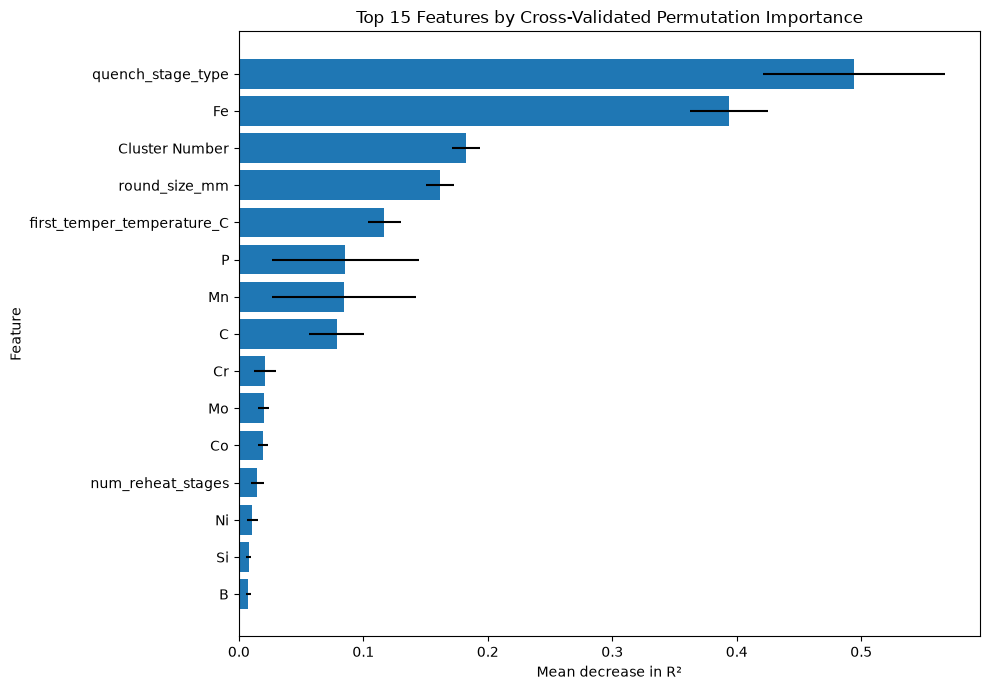

In [34]:
from sklearn.inspection import permutation_importance
from sklearn.model_selection import KFold
import pandas as pd
import numpy as np

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

importance_results = []

for train_idx, test_idx in cv.split(X, y):
    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]

    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]

    final_model.fit(X_train, y_train)

    result = permutation_importance(
        final_model,
        X_test,
        y_test,
        scoring="r2",
        n_repeats=10,
        random_state=42,
        n_jobs=-1
    )

    importance_results.append(
        pd.DataFrame({
            "feature": X.columns,
            "importance": result.importances_mean
        })
    )

importance_df = pd.concat(
    importance_results,
    ignore_index=True
)

feature_importance = (
    importance_df
    .groupby("feature")["importance"]
    .agg(["mean", "std"])
    .sort_values("mean", ascending=False)
)

feature_importance

import matplotlib.pyplot as plt

top_features = feature_importance.head(15).sort_values("mean")

plt.figure(figsize=(10, 7))

plt.barh(
    top_features.index,
    top_features["mean"],
    xerr=top_features["std"]
)

plt.xlabel("Mean decrease in R²")
plt.ylabel("Feature")
plt.title("Top 15 Features by Cross-Validated Permutation Importance")
plt.tight_layout()
plt.show()

##  Error Analysis

Error analysis was conducted to evaluate how prediction errors varied across the dataset and to identify records for which the model performed poorly.

Particular attention was given to errors among high-strength steels and records with incomplete processing information. This analysis helped identify limitations that were not fully apparent from the overall cross-validation metrics.

In [35]:

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import mean_absolute_error, r2_score
import numpy as np

# --------------------------------------------
# 1. Generate out-of-fold predictions
# --------------------------------------------

oof_predictions = cross_val_predict(final_model,X,y,cv=cv,n_jobs=-1)

# --------------------------------------------
# 2. Build diagnostic dataframe
# --------------------------------------------

diagnostic_df = df[
    [
        "Cluster Number",
        "first_temper_temperature_C",
        "quench_temperature_C",
        "case_depth_mm",
        "quench_stage_type",
        "num_reheat_stages",
        "round_size_mm",
        target
    ]
].copy()

diagnostic_df["predicted"] = oof_predictions

diagnostic_df["absolute_error"] = np.abs(
    diagnostic_df[target]
    - diagnostic_df["predicted"]
)

# --------------------------------------------
# 3. Overall performance
# --------------------------------------------

print("OVERALL OUT-OF-FOLD PERFORMANCE")
print("=" * 70)

print("R² :",round(r2_score(y, oof_predictions), 4))

print("MAE:",round(mean_absolute_error(y,oof_predictions),2),"MPa")


# --------------------------------------------
# 4. Error by availability of each feature
# --------------------------------------------

availability_features = [
    "first_temper_temperature_C",
    "quench_temperature_C",
    "case_depth_mm",
    "round_size_mm"
]

print("\nERROR BY FEATURE AVAILABILITY")
print("=" * 70)

for feature in availability_features:

    known = diagnostic_df[feature].notna()

    known_mae = mean_absolute_error(
        diagnostic_df.loc[known, target],
        diagnostic_df.loc[known, "predicted"]
    )

    missing_mae = mean_absolute_error(
        diagnostic_df.loc[~known, target],
        diagnostic_df.loc[~known, "predicted"]
    )

    print(f"\n{feature}")
    print(
            f"  Known   : {known.sum():4d} rows | "
            f"MAE = {known_mae:.2f} MPa"
        )
    print(
            f"  Missing : {(~known).sum():4d} rows | "
            f"MAE = {missing_mae:.2f} MPa"
        )


# --------------------------------------------
# 5. Error by cluster
# --------------------------------------------

cluster_errors = (
    diagnostic_df
    .groupby("Cluster Number")
    .agg(
        count=(target, "size"),
        mean_yield=(target, "mean"),
        mean_absolute_error=("absolute_error", "mean"),
        median_absolute_error=("absolute_error", "median"),
        max_absolute_error=("absolute_error", "max")
    )
    .reset_index()
)

print("\nERROR BY CLUSTER")
print("=" * 70)

print(cluster_errors.round(2).to_string(index=False))


# --------------------------------------------
# 6. High-strength subset
# --------------------------------------------

high_strength = diagnostic_df[target] >= 1200

print("\nHIGH-STRENGTH SUBSET")
print("=" * 70)

print("Count:",high_strength.sum())

print("MAE:",
    round(mean_absolute_error(
            diagnostic_df.loc[high_strength, target],
            diagnostic_df.loc[high_strength, "predicted"]),
        2),"MPa")

print("R²:",round(r2_score(
            diagnostic_df.loc[high_strength, target],
            diagnostic_df.loc[high_strength, "predicted"]
        ),4))


# --------------------------------------------
# 7. Largest remaining errors
# --------------------------------------------

print("\n20 LARGEST OUT-OF-FOLD ERRORS")
print("=" * 70)

largest_errors = (
    diagnostic_df
    .sort_values(
        "absolute_error",
        ascending=False
    )
    .head(20)
)

print(
    largest_errors[
        [
            "Cluster Number",
            target,
            "predicted",
            "absolute_error",
            "first_temper_temperature_C",
            "quench_temperature_C",
            "case_depth_mm",
            "round_size_mm",
            "quench_stage_type",
            "num_reheat_stages"
        ]
    ]
    .round(2)
    .to_string(index=False)
)
    

OVERALL OUT-OF-FOLD PERFORMANCE
R² : 0.9389
MAE: 36.65 MPa

ERROR BY FEATURE AVAILABILITY

first_temper_temperature_C
  Known   : 1582 rows | MAE = 28.75 MPa
  Missing : 1652 rows | MAE = 44.21 MPa

quench_temperature_C
  Known   :  842 rows | MAE = 15.16 MPa
  Missing : 2392 rows | MAE = 44.21 MPa

case_depth_mm
  Known   :   78 rows | MAE = 26.29 MPa
  Missing : 3156 rows | MAE = 36.90 MPa

round_size_mm
  Known   : 2161 rows | MAE = 30.96 MPa
  Missing : 1073 rows | MAE = 48.11 MPa

ERROR BY CLUSTER
 Cluster Number  count  mean_yield  mean_absolute_error  median_absolute_error  max_absolute_error
              0    501      836.66                78.97                  55.41              600.80
              1    323      365.70                47.79                  32.38              294.29
              2    248      593.55                75.91                  30.02             1202.40
              3    196      440.53                73.81                  63.91              246.

### Interpretation of Prediction Errors

The model achieved strong overall predictive performance, but the error analysis revealed substantial differences across material groups.

Prediction errors were particularly high among steels with yield strengths of at least 1,200 MPa. This indicates that the model was less effective at predicting the upper end of the yield-strength distribution.

Some large errors were associated with records in which important processing details were unavailable. Differences in heat-treatment conditions can be associated with substantial differences in mechanical properties, even among
steels with similar chemical compositions.

The findings suggest that incomplete processing information and the limited representation of certain high-strength conditions constrained predictive performance. These limitations should be considered when interpreting the model's results.

## Actual vs Predicted Yield Strength

To evaluate the model's predictions visually, actual yield strength values are compared with out-of-fold predictions generated using five-fold cross-validation.

Each observation is predicted by a model that was not trained on that observation. This provides a more realistic assessment of predictive performance than comparing predictions on the training data.

The dashed diagonal line represents perfect prediction. Points closer to this line indicate more accurate predictions, while points farther away indicate larger prediction errors.

Out-of-fold R²: 0.9389
Out-of-fold MAE: 36.65 MPa


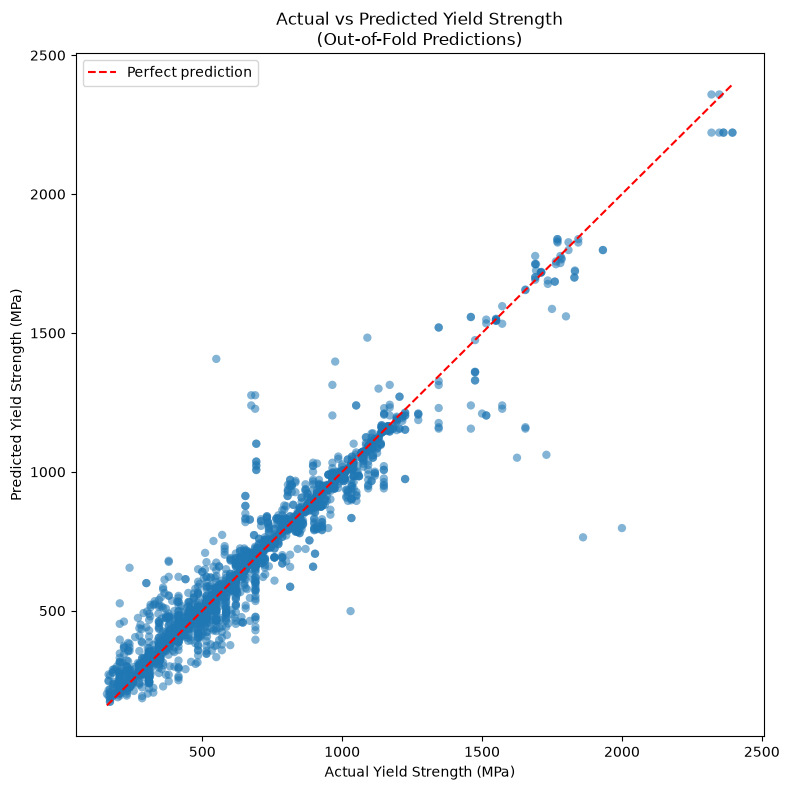

In [36]:
# Actual vs predicted yield strength using out-of-fold predictions

import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_absolute_error

# Calculate evaluation metrics
oof_r2 = r2_score(y, oof_predictions)
oof_mae = mean_absolute_error(y, oof_predictions)

# Print the corresponding metrics
print(f"Out-of-fold R²: {oof_r2:.4f}")
print(f"Out-of-fold MAE: {oof_mae:.2f} MPa")

# Determine plot limits
lower_limit = min(y.min(), oof_predictions.min())
upper_limit = max(y.max(), oof_predictions.max())

# Create the plot
plt.figure(figsize=(8, 8))

plt.scatter(
    y,
    oof_predictions,
    alpha=0.55,
    edgecolors="none"
)

# Perfect-prediction reference line
plt.plot(
    [lower_limit, upper_limit],
    [lower_limit, upper_limit],
    "r--",
    label="Perfect prediction"
)

plt.xlabel("Actual Yield Strength (MPa)")
plt.ylabel("Predicted Yield Strength (MPa)")
plt.title("Actual vs Predicted Yield Strength\n(Out-of-Fold Predictions)")
plt.legend()
plt.tight_layout()
plt.show()



### Interpretation of the Actual vs Predicted Plot

The actual-versus-predicted plot provides a visual assessment of the model's predictive performance.

- Points close to the diagonal line represent predictions close to the measured yield strength.
- Points above the line represent overpredictions.
- Points below the line represent underpredictions.
- Points farther from the line represent larger prediction errors.

Strong overall performance does not necessarily imply equally reliable predictions across all yield-strength ranges or steel clusters.

The plot supports the numerical evaluation of the model but does not establish that every individual prediction is reliable.

## Discussion

The results indicate that machine learning can predict steel yield strength from a combination of chemical composition and processing-related information within this dataset.

The final Random Forest model achieved strong cross-validated performance, with an R² of approximately 0.939 and a mean absolute error of approximately 36.65 MPa. These results indicate that the model explains a substantial proportion of the observed variation in yield strength and produces predictions that are reasonably close to the measured values on average.

Feature-importance analysis identified quench stage type, iron content, cluster number, round size, and first tempering temperature among the most informative features for prediction. This suggests that processing-related information and dataset groupings provide useful predictive information alongside chemical composition.

The error analysis also showed that predictive performance was not uniform across all observations. Errors varied across steel clusters, and the high-strength subset was more difficult to predict than the dataset overall. Missing processing information was also associated with higher prediction errors, although this association should not be interpreted as proof that missing information directly caused those errors.

These findings support the use of processing information as part of a data-driven approach to predicting steel yield strength. However, the results are specific to the available dataset, and further validation is necessary before the model can be considered reliable for unfamiliar steels or practical engineering decisions.

## Limitations

Three major limitations were identified.

1. **Incomplete processing information**

   Several processing variables were unavailable for a substantial portion
   of the dataset.

2. **Limited microstructural information**

   The dataset does not directly provide detailed microstructural
   information, which can strongly influence mechanical properties.

3. **High-strength prediction**

   Prediction remained substantially less reliable for steels with yield
   strength of 1200 MPa or greater.

## Future Work

Future work could focus on:

1. Obtaining more complete processing records.
2. Increasing the number of high-strength steel observations.
3. Comparing Random Forest with other nonlinear models such as gradient boosting.

## Conclusion

This project investigated whether machine learning could predict the yield strength of steels from chemical composition and processing information.

The results show that incorporating processing information substantially improves predictive performance compared with using chemical composition alone.

However, incomplete processing information, limited microstructural information, and reduced performance for high-strength steels remain important limitations.